# Full MNIST: SONG speed, held-out accuracy, and visualization

This report uses the [Keras MNIST archive](https://keras.io/api/datasets/mnist/) and its predefined **60,000 train / 10,000 test** split. Each image is flattened to 784 float32 pixels and divided by 255. SONG fits on the training images only. Labels are used afterward for prototype votes and validation probes, never to fit the embedding. Seed 42, 50-component internal PCA, 4 Numba threads, and 4 BLAS threads were used. Both 30 and 100 self-organization steps are shown; 100 is SONG's default. Timings exclude a small Numba warm-up and data loading, and each configuration was run once on an Apple Silicon Mac. Raw phase times are wall-clock measurements, not a statistical performance comparison.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

root = Path('reports')
fig = root / 'figures'
runs = {'30 steps': json.loads((root / 'mnist_profile.json').read_text()),
        '100 steps': json.loads((root / 'mnist_profile_100steps_full.json').read_text())}
assert all(run['train_size'] == 60000 and run['test_size'] == 10000 for run in runs.values())
assert len({run['data_sha256'] for run in runs.values()}) == 1
rows = []
for name, run in runs.items():
    m = run['metrics']
    rows.append({'run': name, 'prototypes': run['song_prototypes'],
                 'fit_s': m['song_fit_s'], 'dispersion_train_s': m['dispersion_train_transform_s'],
                 'prototype_test_accuracy': m['prototype_test_accuracy'],
                 'core_2d_test_accuracy': m['core_2d_test_accuracy'],
                 'dispersion_cross_frame_accuracy': m['dispersion_cross_frame_test_accuracy'],
                 'PCA50_linear_test_accuracy': m['pca_linear_test_accuracy'],
                 'peak_RSS_GiB': m['peak_rss_gib']})
summary = pd.DataFrame(rows).set_index('run')
display(summary.round(3))

,prototypes,fit_s,dispersion_train_s,prototype_test_accuracy,core_2d_test_accuracy,dispersion_cross_frame_accuracy,PCA50_linear_test_accuracy,peak_RSS_GiB
run,,,,,,,,
30 steps,1049,1.748,8.010,0.916,0.909,0.888,0.913,1.505
100 steps,1557,5.035,7.924,0.938,0.935,0.909,0.913,1.442


## What the accuracy measures

**Prototype voting:** assign each training image to its nearest SONG prototype, give each prototype its majority training label, and predict a test image from its nearest prototype. **Core 2D probe:** fit a 5-neighbor classifier on the training core coordinates and evaluate all 10,000 test coordinates. These use one shared fitted SONG map. **PCA-50 linear probe:** supervised logistic regression on SONG's fitted PCA coordinates; this is context, not the same model as SONG. **Dispersion cross-frame probe:** train and test each call `transform` separately, which refits UMAP. Its score is a diagnostic because the two sets do not have a guaranteed common coordinate frame. See [issue #7](https://github.com/damithsenanayake/SONG/issues/7).

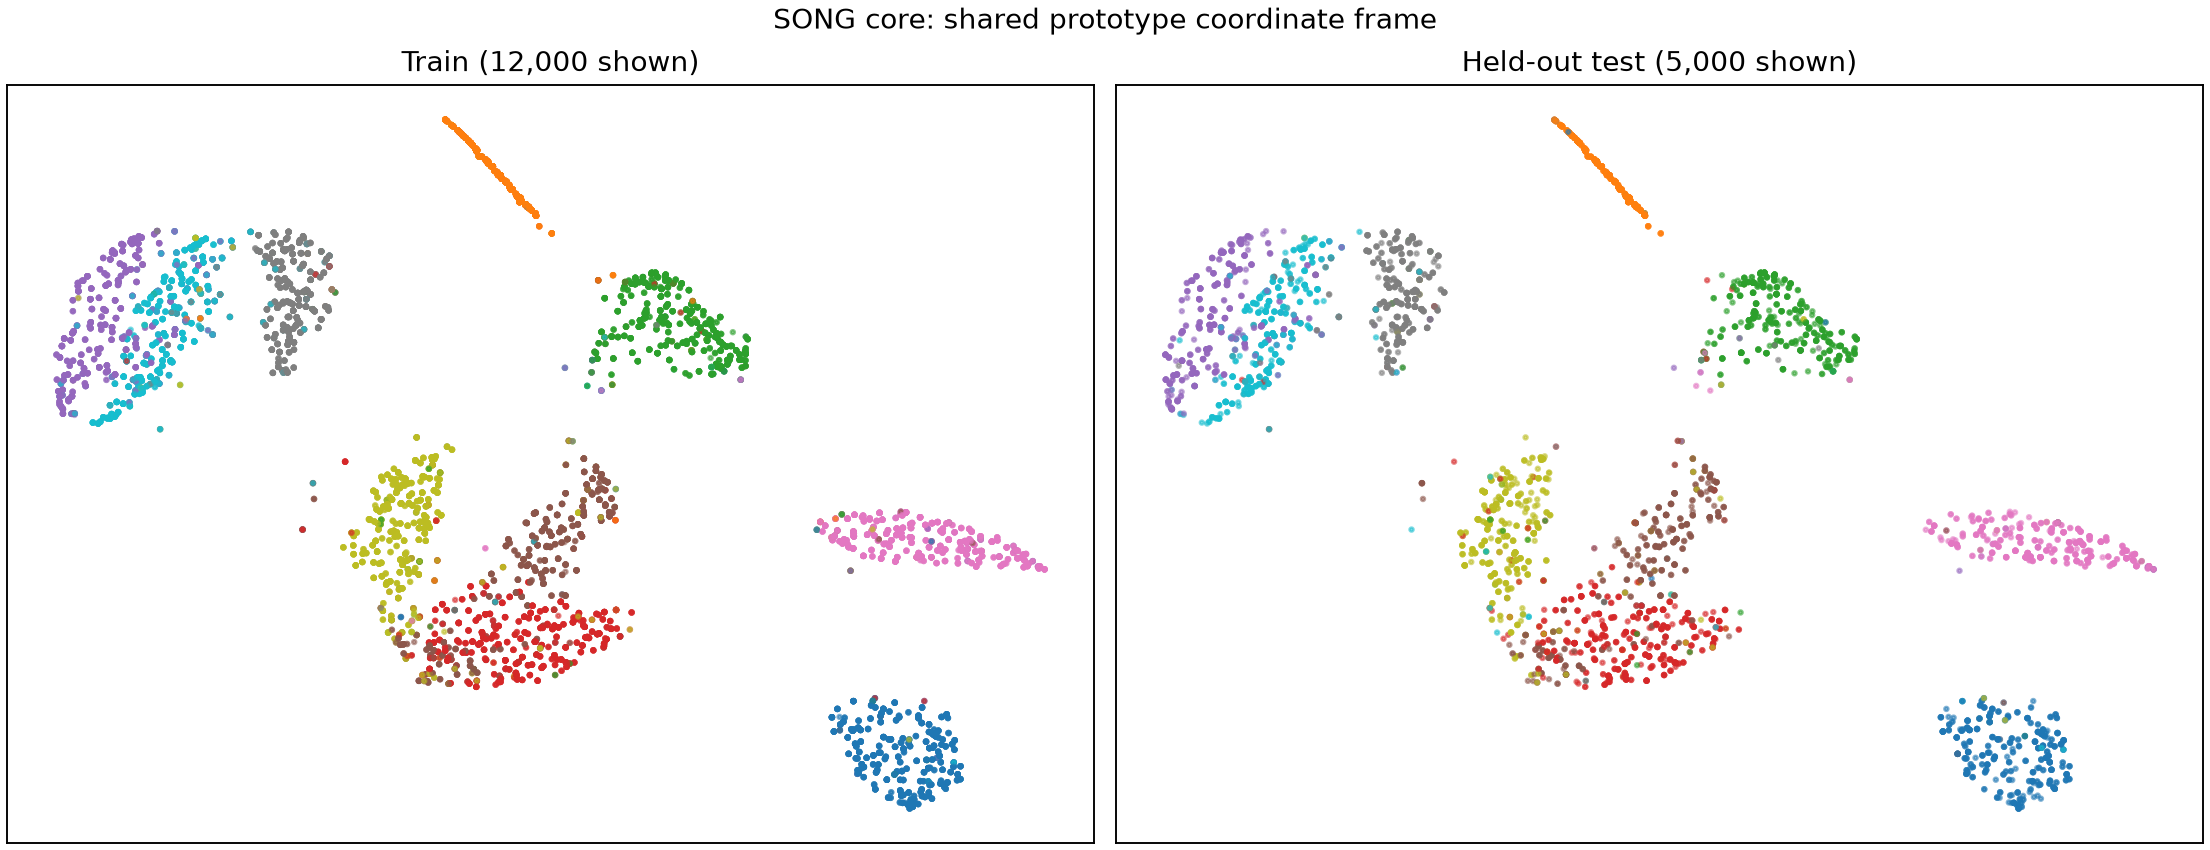

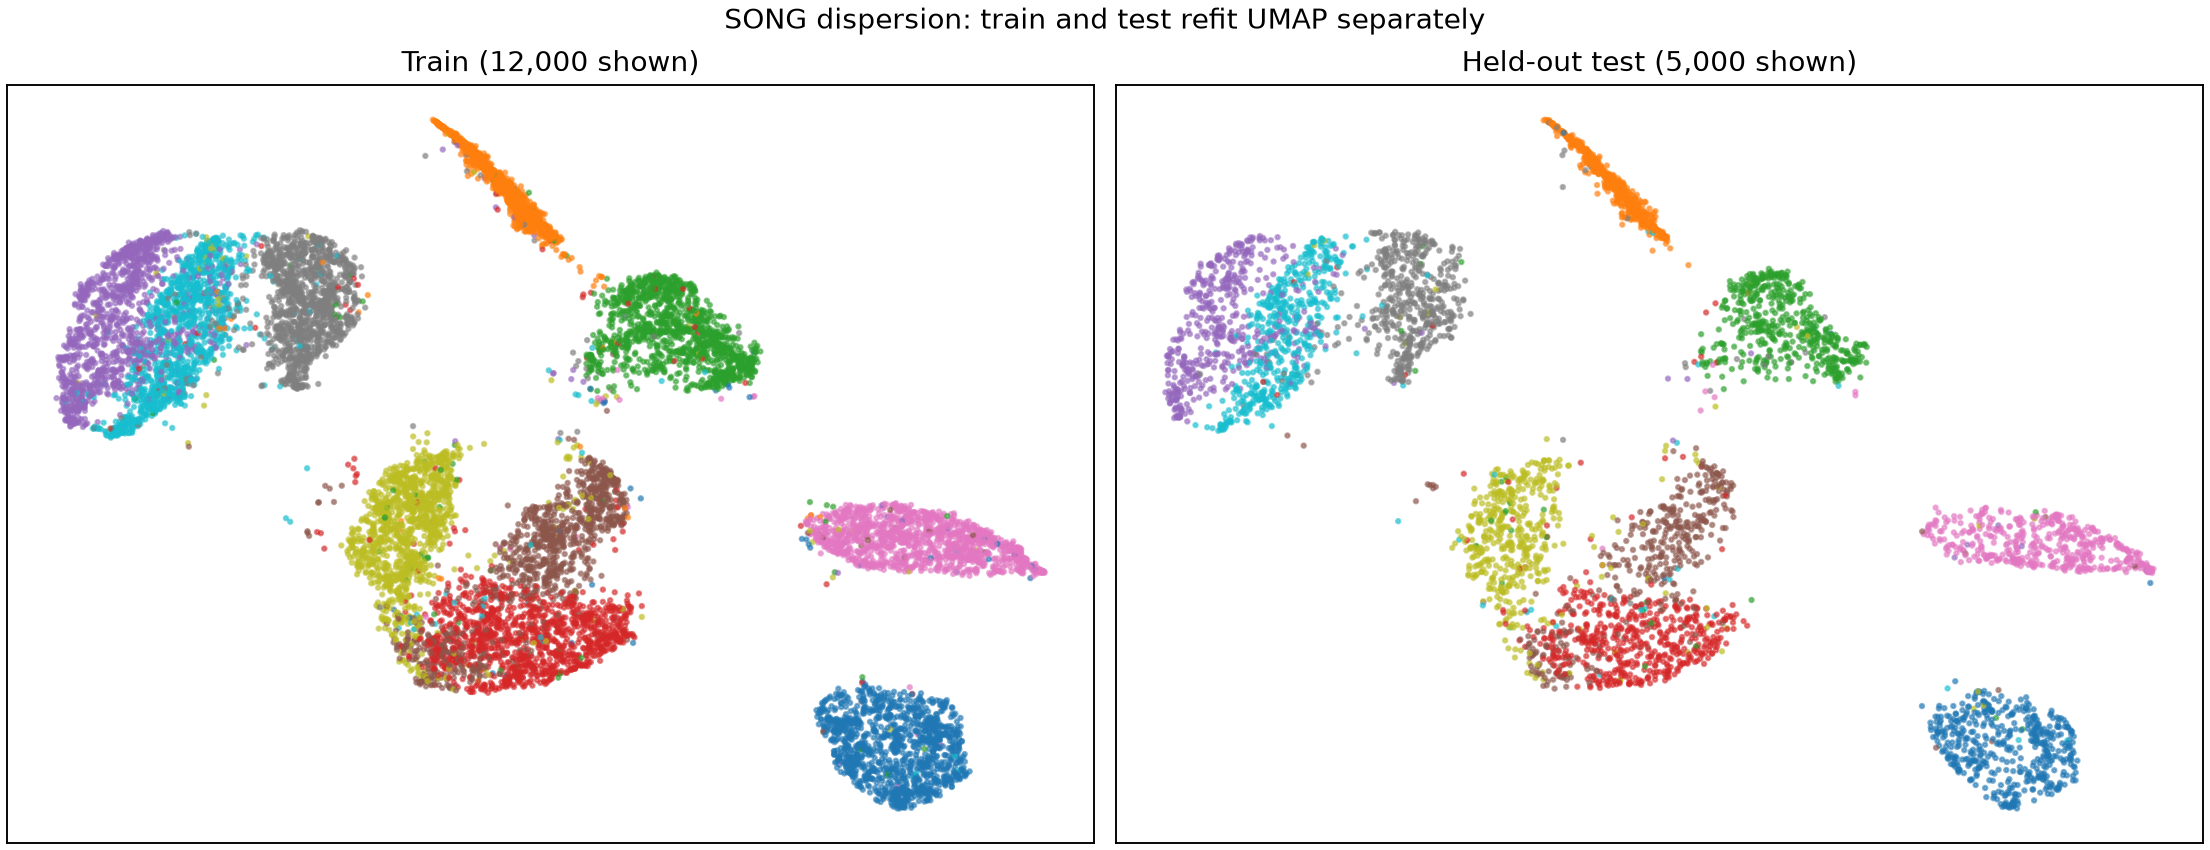

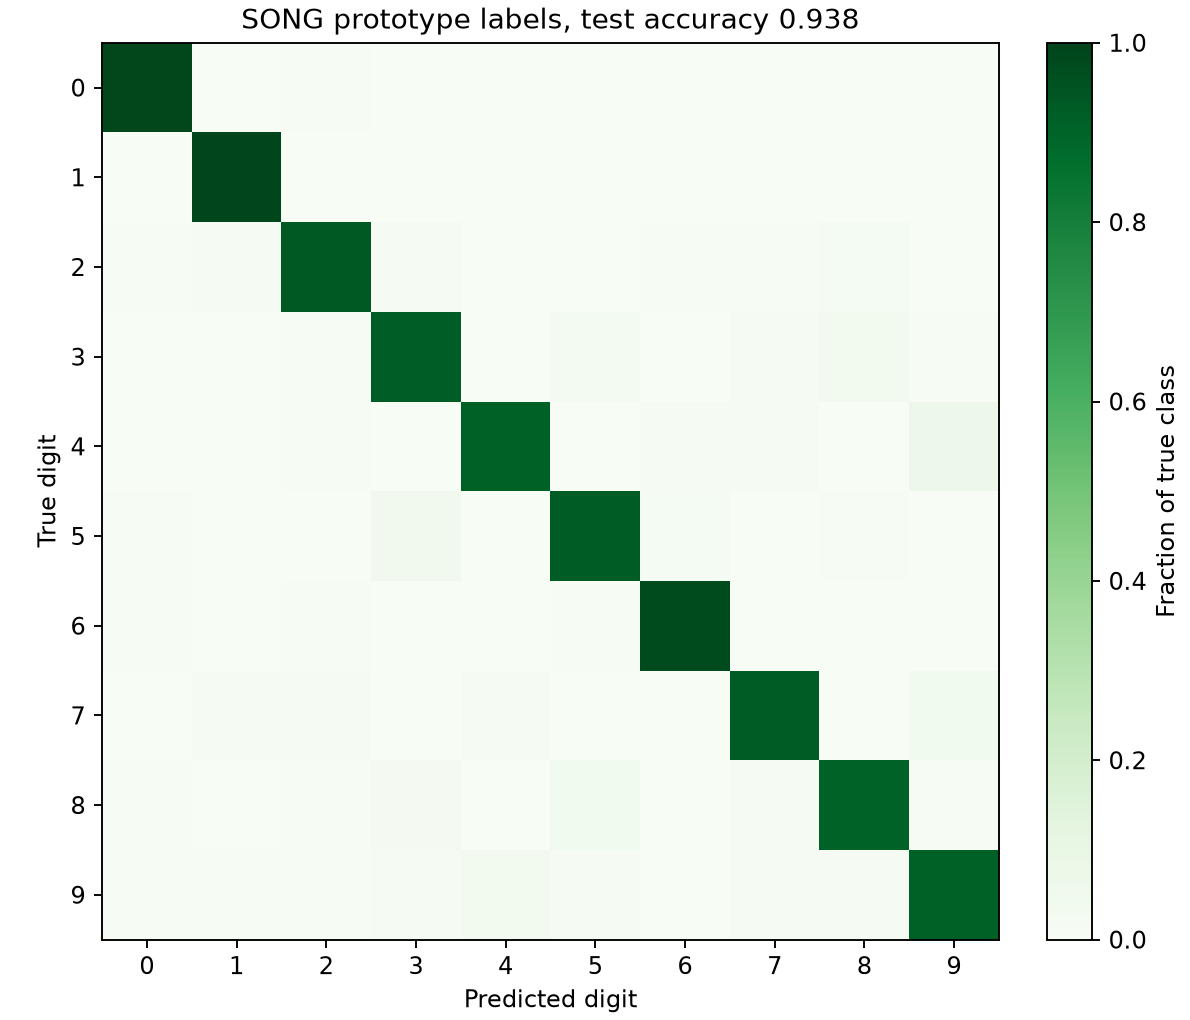

In [2]:
display(Image(filename=str(fig / 'mnist_song_core_train_test_100steps_full.png')))
display(Image(filename=str(fig / 'mnist_song_dispersion_train_test_100steps_full.png')))
display(Image(filename=str(fig / 'mnist_prototype_confusion_100steps_full.png')))

The scatter panels show sampled points (12,000 training and 5,000 test) to keep overplotting manageable; every image contributes to the reported accuracy. The core map has repeated coordinates because samples assigned to one prototype share its 2D position. Increasing from 30 to 100 steps increases the number of prototypes and improves held-out accuracy in this run.

run,100 steps,30 steps
stage,,
PCA fit,0.036,0.046
PCA transform,0.065,0.066
bulk_grow_with_drifters,0.028,0.009
sq_eucl_opt,0.508,0.157
train_for_batch_batch,4.202,1.430


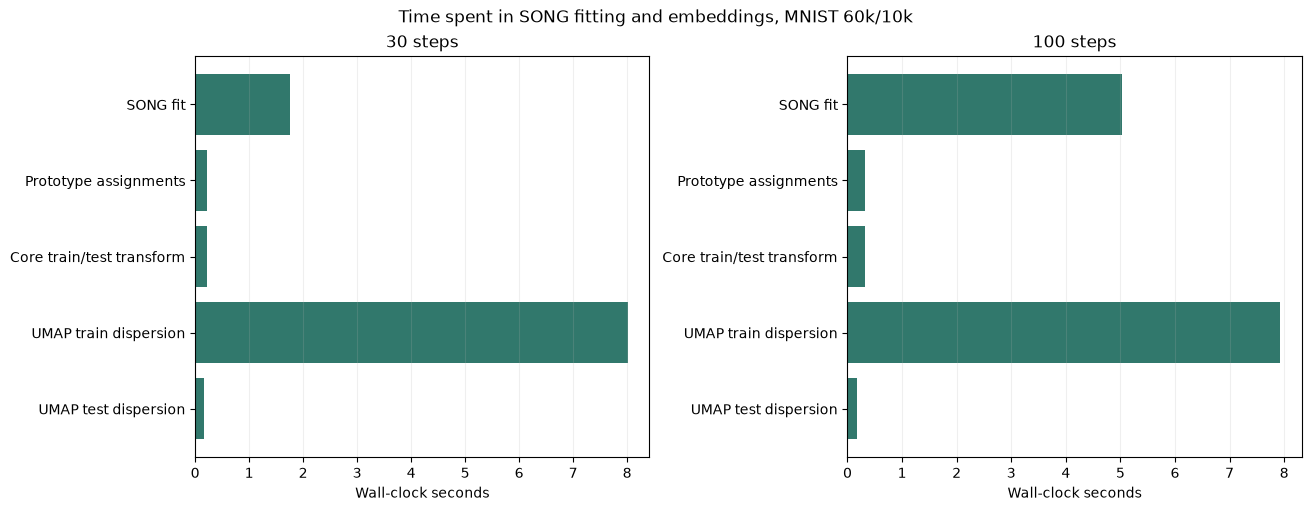

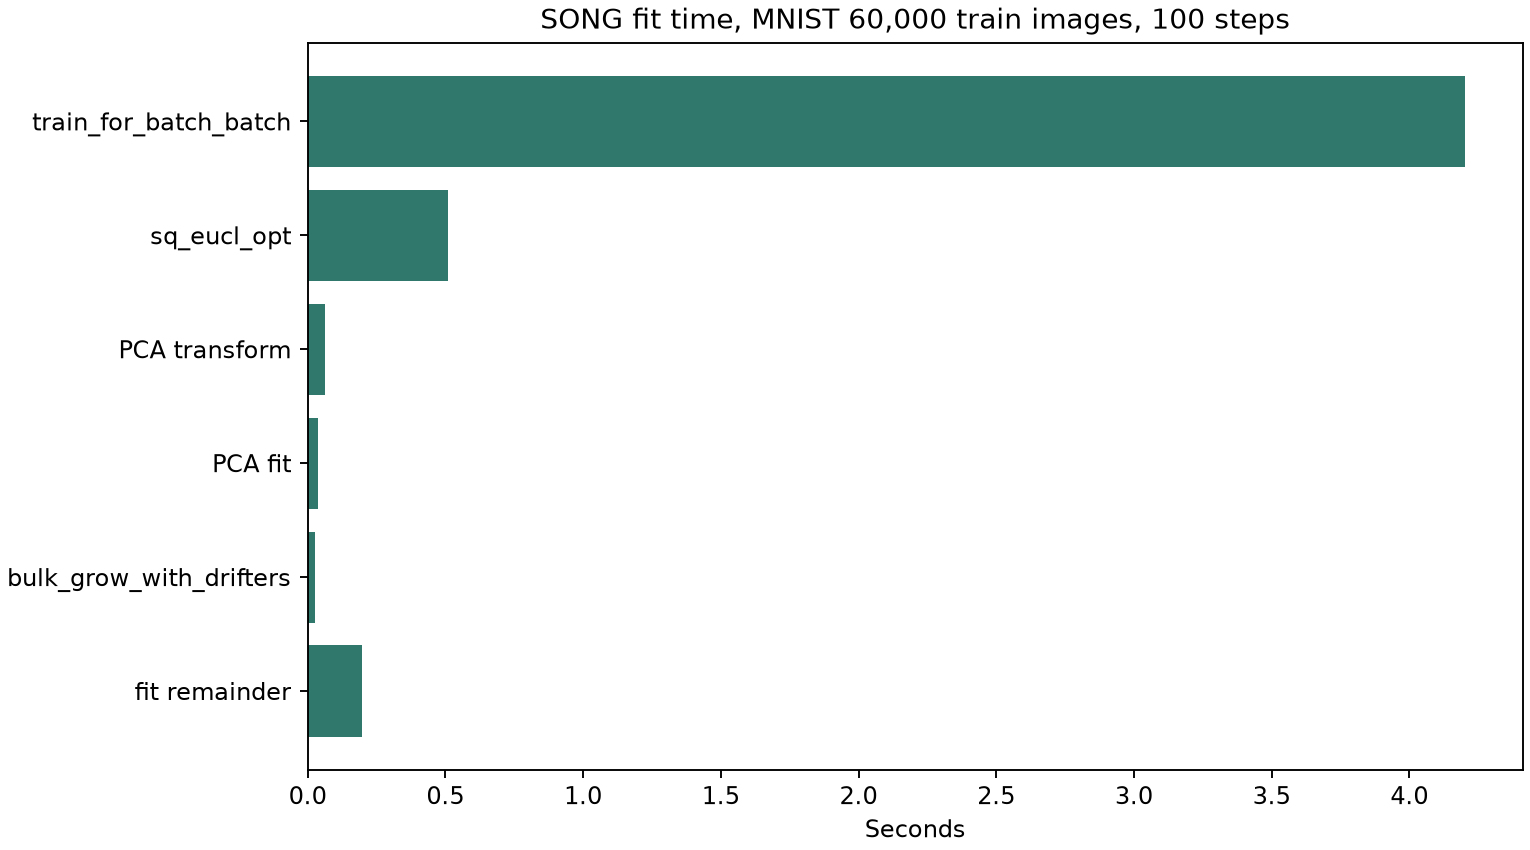

In [3]:
fit_stages = pd.DataFrame([{'run': name, 'stage': stage, 'seconds': seconds}
                           for name, run in runs.items()
                           for stage, seconds in run['stage_times'].items()])
display(fit_stages.pivot(index='stage', columns='run', values='seconds').fillna(0).round(3))

fig_obj, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, (name, run) in zip(axes, runs.items()):
    m = run['metrics']
    stages = [('SONG fit', m['song_fit_s']),
              ('Prototype assignments', m['representative_assignments_s']),
              ('Core train/test transform', m['core_train_transform_s'] + m['core_test_transform_s']),
              ('UMAP train dispersion', m['dispersion_train_transform_s']),
              ('UMAP test dispersion', m['dispersion_test_transform_s'])]
    ax.barh([s[0] for s in stages][::-1], [s[1] for s in stages][::-1], color='#31786c')
    ax.set(xlabel='Wall-clock seconds', title=name)
    ax.grid(axis='x', alpha=.2)
fig_obj.suptitle('Time spent in SONG fitting and embeddings, MNIST 60k/10k')
fig_obj.savefig(fig / 'mnist_pipeline_profile.png', dpi=170)
plt.show()
display(Image(filename=str(fig / 'mnist_song_fit_profile_100steps_full.png')))

At 100 steps, `train_for_batch_batch` accounts for about 4.20 of 5.04 fitting seconds. Pairwise squared distances take about 0.51 seconds. The 60,000-point UMAP dispersion takes about 7.92 seconds, so refinement is the largest stage in the full pipeline. `train_for_batch_batch` updates shared prototype, graph, and embedding state sequentially for each sample; parallelizing its loop requires an algorithmic change. The distance kernel is already parallel over input-row blocks. Its first 100-row batch has only three complete 32-row blocks, but the later 1,000-row chunks have 31 blocks available to parallel workers.

## Is nearest-neighbor search the bottleneck?

SONG's nearest-prototype lookup and UMAP's approximate kNN search are different operations. The 100-step full run measured SONG core lookup on 60,000 training images at about **0.27 s**. A focused second run timed UMAP's 60,000-point refinement: nearest-neighbor search **5.26 s**, fuzzy graph construction **1.46 s**, layout optimization **0.75 s**, total **7.49 s**. Thus kNN search consumes about **70% of UMAP refinement** in that run. These stage timers are non-overlapping wrappers around UMAP's `nearest_neighbors`, `fuzzy_simplicial_set`, and `simplicial_set_embedding`. See the [raw stage JSON](mnist_neighbor_stages.json).

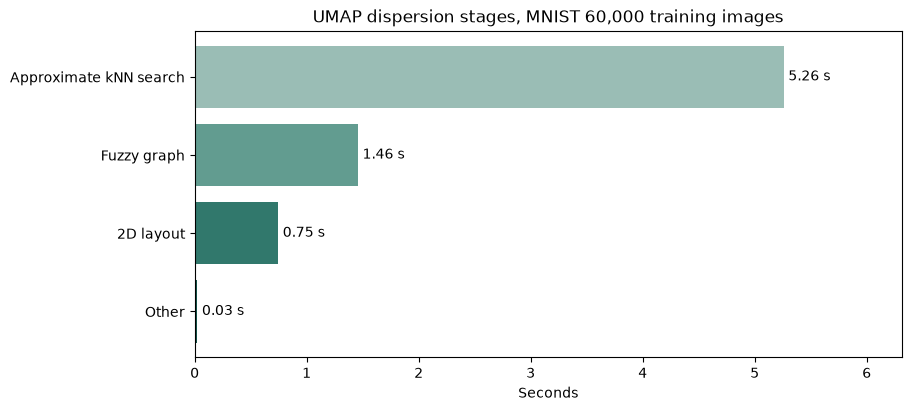

,stage,seconds
0,Approximate kNN search,5.260
1,Fuzzy graph,1.458
2,2D layout,0.746
3,Other,0.025


In [4]:
neighbor = json.loads((root / 'mnist_neighbor_stages.json').read_text())
labels = ['Approximate kNN search', 'Fuzzy graph', '2D layout', 'Other']
values = [neighbor['umap_stage_s']['nearest_neighbors'],
          neighbor['umap_stage_s']['fuzzy_simplicial_set'],
          neighbor['umap_stage_s']['simplicial_set_embedding'],
          neighbor['umap_other_s']]
fig_obj, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
ax.barh(labels[::-1], values[::-1], color=['#9abdb5', '#629c90', '#31786c', '#135348'][::-1])
ax.set(xlabel='Seconds', title='UMAP dispersion stages, MNIST 60,000 training images')
for index, value in enumerate(values[::-1]):
    ax.text(value + .04, index, f'{value:.2f} s', va='center')
ax.set_xlim(0, max(values) * 1.2)
fig_obj.savefig(fig / 'mnist_umap_neighbor_stages.png', dpi=170)
plt.show()
display(pd.DataFrame({'stage': labels, 'seconds': values}).round(3))

,samples,prototypes,features,threads,median_ms,p25_ms,p75_ms
0,100,1050,50,1,0.768,0.753,0.774
1,100,1050,50,2,0.598,0.579,0.619
2,100,1050,50,4,0.399,0.391,0.405
3,100,1050,50,8,0.410,0.403,0.422
4,1000,1050,50,1,6.625,6.592,6.793
5,1000,1050,50,2,3.705,3.658,3.751
6,1000,1050,50,4,2.023,2.006,2.054
7,1000,1050,50,8,1.202,1.182,1.206
8,1000,1500,50,1,9.484,9.374,9.661
9,1000,1500,50,2,5.189,5.143,5.235


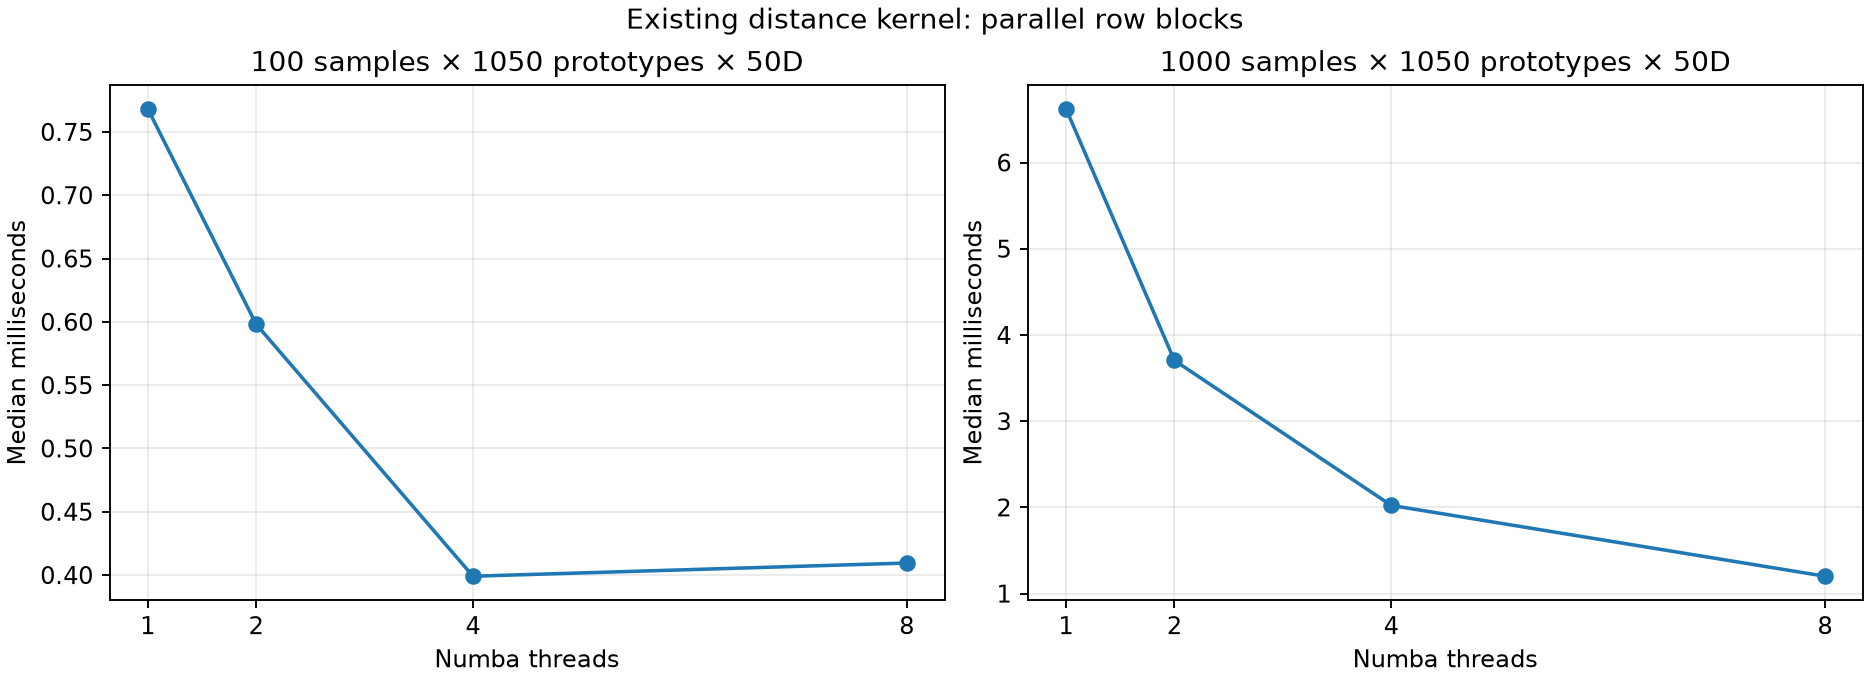

1,000 × 1,050 × 50D: 5.51× kernel speedup at 8 vs 1 thread


In [5]:
distance = pd.read_csv(root / 'mnist_distance_threads.csv')
display(distance.round(3))
display(Image(filename=str(fig / 'mnist_distance_threads.png')))
base = distance[(distance.samples == 1000) & (distance.prototypes == 1050)].set_index('threads').median_ms
print(f'1,000 × 1,050 × 50D: {base.loc[1] / base.loc[8]:.2f}× kernel speedup at 8 vs 1 thread')

The thread sweep times only `sq_eucl_opt`, with 35 post-warm-up repetitions per shape and thread count. Outputs were checked against the one-thread result. The larger 1,000×1,050 kernel scales across multiple vector pairs, confirming Numba's `prange` is active. A faster distance kernel can save at most the measured distance share of fitting time; the serial prototype update and UMAP refinement are the stronger optimization targets. These measurements are machine-specific and should be rerun before changing defaults.

## Reproduce

From the repository root:

```bash
NUMBA_NUM_THREADS=4 OPENBLAS_NUM_THREADS=4 .venv/bin/python reports/mnist_profile.py --steps 30
NUMBA_NUM_THREADS=4 OPENBLAS_NUM_THREADS=4 .venv/bin/python reports/mnist_profile.py --steps 100 --run-label 100steps_full
NUMBA_NUM_THREADS=8 OPENBLAS_NUM_THREADS=4 .venv/bin/python reports/distance_threads.py
NUMBA_NUM_THREADS=4 OPENBLAS_NUM_THREADS=4 .venv/bin/python reports/mnist_neighbor_stages.py
```

The MNIST archive is downloaded into ignored `data/` on first use. The SHA-256 checksum and exact settings are saved in each JSON report. The image files and CSV results are committed; the downloaded archive and embedding arrays remain local.